# Who Finishes the Job?
**Paper:** Takerngsaksiri et al. 2026 – Follow-Up Fixes and Commit Authorship on AI Coding Agent PRs
**Data:** https://github.com/wannita901/pr-fix-authorship

**What is in the data:** 2,510 candidate pairs **AI PR (P) → later PR (Q)** in the same repo, within 30 days, touching the same files (from AIDev-pop). An LLM judge (Claude Opus) labelled each pair: *Direct fix*, *Related touch* or *Unrelated*. The code changes of both PRs are kept.

**One row of the main table =** one pair (AI PR → later PR)

This notebook has 3 parts:
1. **First look** – the files, some lines, all the columns, the size.
2. **Data-science view** – size, dates, **numbers per AI agent**, **how the agent is involved** (tables saved in `tables/`).
3. **Charts** – what kind of change · fixes per AI agent · who wrote the fix · how fast the fix comes · extra (saved in `charts/`).

In [1]:
import sys, os, json
sys.path.insert(0, "..")          # to find common.py in the parent folder
from common import *

## 0. Get the data

In [2]:
root = get_repo("https://github.com/wannita901/pr-fix-authorship", "pr-fix-authorship")
J = os.path.join(root, "data", "judge")

Data folder: ../../data/01_WhoFinishes/pr-fix-authorship


## 1. First look
### Files in the repository

In [3]:
list_files(root).head(15)

,file,size_MB
0,data/judge/rq1_judge_cases_population_12k.json.gz,4.91
1,data/judge/rq1_llm_judge_pop_anthropic_claude-opus-4-8_l...,1.36


### Main table: the judge verdict of each pair

In [4]:
v = pd.read_csv(os.path.join(J, "rq1_llm_judge_pop_anthropic_claude-opus-4-8_low.csv"))
cols_v = overview(v, "Judge verdicts")

**Judge verdicts** — **2,510 rows × 13 columns** (1.5 MB in memory)

*First 5 lines:*

,pair_id,provider,model,agent,q_is_human,label,confidence,n_shared,context_complete,rationale,evidence_files,p_url,q_url
0,1,anthropic,claude-opus-4-8,Devin,False,Unrelated/mislabeled,0.95,1,True,P upgraded the Vercel AI SDK (lockfile deps); Q fixes au...,pnpm-lock.yaml,https://github.com/different-ai/note-companion/pull/294,https://github.com/different-ai/note-companion/pull/307
1,2,anthropic,claude-opus-4-8,Devin,False,Unrelated/mislabeled,0.92,1,True,P adds search-grounding chat UI; Q fixes audio-file link...,NaN,https://github.com/different-ai/note-companion/pull/300,https://github.com/different-ai/note-companion/pull/307
2,3,anthropic,claude-opus-4-8,Devin,False,Unrelated/mislabeled,0.95,1,True,P adds a manual release GitHub Actions workflow; Q fixes...,NaN,https://github.com/different-ai/note-companion/pull/301,https://github.com/different-ai/note-companion/pull/307
3,4,anthropic,claude-opus-4-8,Devin,False,Unrelated/mislabeled,0.95,1,True,P adds a Next.js landing package; Q fixes audio file lin...,NaN,https://github.com/different-ai/note-companion/pull/303,https://github.com/different-ai/note-companion/pull/307
4,11,anthropic,claude-opus-4-8,Devin,False,Unrelated/mislabeled,0.95,1,True,P adds output_file interpolation tests; Q adds a manager...,tests/crew_test.py,https://github.com/crewAIInc/crewAI/pull/1814,https://github.com/crewAIInc/crewAI/pull/1820


*All columns:*

,column,type,missing_%,unique,example
0,pair_id,int64,0.0,2510,1
1,provider,str,0.0,1,anthropic
2,model,str,0.0,1,claude-opus-4-8
3,agent,str,0.0,5,Devin
4,q_is_human,bool,0.0,2,False
5,label,str,0.0,3,Unrelated/mislabeled
6,confidence,float64,0.0,25,0.95
7,n_shared,int64,0.0,27,1
8,context_complete,bool,0.0,1,True
9,rationale,str,0.0,2510,P upgraded the Vercel AI SDK (lockfile deps); Q fi


### Second table: the details of each pair (titles, commits, code changes)
The column `shared` holds, for every file both PRs changed, the AI patch (`p_patch`) and the **fix patch** (`q_patch`).

In [5]:
cases = pd.DataFrame(load_json(os.path.join(J, "rq1_judge_cases_population_12k.json")))
cols_c = overview(cases.drop(columns=["p_body", "q_body"]), "Pair details")

**Pair details** — **2,510 rows × 28 columns** (2.1 MB in memory)

*First 5 lines:*

,pair_id,agent,consensus_label,label_1,label_2,reason_note,p_url,q_url,p_title,q_title,p_commits,q_commits,day_gap,n_intervening,q_is_human,q_type,q_references_p,shared,n_shared,n_substantive,full_diff,q_only,p_only,n_q_only,n_p_only,context_complete,p_id,q_id
0,1,Devin,None,None,None,,https://github.com/different-ai/note-companion/pull/294,https://github.com/different-ai/note-companion/pull/307,feat: Update Vercel AI SDK to v4,Fix: ensure audio link is embedded,[chore: migrate to Vercel AI SDK 4.0\n\nCo-Authored-By: ...,"[push, fix: ensure audio file link is embedded in contai...",16,3,False,,False,"[{'name': 'pnpm-lock.yaml', 'boilerplate': True, 'p_patc...",1,0,False,[],[],0,0,True,2757674020,2777347182
1,2,Devin,None,None,None,,https://github.com/different-ai/note-companion/pull/300,https://github.com/different-ai/note-companion/pull/307,Add search grounding to chat,Fix: ensure audio link is embedded,"[fix search grounding, fix: handle metadata through mess...","[push, fix: ensure audio file link is embedded in contai...",15,2,False,,False,"[{'name': 'pnpm-lock.yaml', 'boilerplate': True, 'p_patc...",1,0,False,[],[],0,0,True,2758742372,2777347182
2,3,Devin,None,None,None,,https://github.com/different-ai/note-companion/pull/301,https://github.com/different-ai/note-companion/pull/307,Add manual release workflow,Fix: ensure audio link is embedded,[Add manual release workflow with release-in-progress ch...,"[push, fix: ensure audio file link is embedded in contai...",14,1,False,,False,"[{'name': 'pnpm-lock.yaml', 'boilerplate': True, 'p_patc...",1,0,False,[],[],0,0,True,2759596477,2777347182
3,4,Devin,None,None,None,,https://github.com/different-ai/note-companion/pull/303,https://github.com/different-ai/note-companion/pull/307,feat: add landing package with shadcn and v0 components,Fix: ensure audio link is embedded,[chore: update pnpm lock file\n\nCo-Authored-By: ben <be...,"[push, fix: ensure audio file link is embedded in contai...",14,0,False,,False,"[{'name': 'pnpm-lock.yaml', 'boilerplate': True, 'p_patc...",1,0,False,[],[],0,0,True,2759788051,2777347182
4,11,Devin,None,None,None,,https://github.com/crewAIInc/crewAI/pull/1814,https://github.com/crewAIInc/crewAI/pull/1820,Fix interpolation for output_file in Task (#1803),fix(manager_llm): handle coworker role name case/whitesp...,[fix: add _original_output_file private attribute to fix...,[fix(manager_llm): improve error handling and add debug ...,1,0,False,,False,"[{'name': 'tests/crew_test.py', 'boilerplate': False, 'p...",1,1,False,[],[],0,0,True,2762078403,2763395657


*All columns:*

,column,type,missing_%,unique,example
0,pair_id,int64,0.0,2510,1
1,agent,str,0.0,5,Devin
2,consensus_label,object,100.0,0,
3,label_1,object,100.0,0,
4,label_2,object,100.0,0,
5,reason_note,str,0.0,1,
6,p_url,str,0.0,1363,https://github.com/different-ai/note-companion/pul
7,q_url,str,0.0,845,https://github.com/different-ai/note-companion/pul
8,p_title,str,0.0,1351,feat: Update Vercel AI SDK to v4
9,q_title,str,0.0,841,Fix: ensure audio link is embedded


## 2. Data-science view
### Size and dates

In [6]:
d = v.merge(cases[["pair_id", "day_gap", "q_type", "shared", "p_title", "q_title"]], on="pair_id")
d["repo"] = d["p_url"].str.extract(r"github\.com/([^/]+/[^/]+)")
d["agent"] = d["agent"].map(agent_of)
d["fixed_by"] = d["q_is_human"].map({True: "Human", False: "AI agent"})
print("Candidate pairs :", len(d))
print("Repositories    :", d["repo"].nunique())
print("AI PRs (P)      :", cases["p_id"].nunique(), "| later PRs (Q):", cases["q_id"].nunique())
print("Direct fixes    :", (d["label"] == "Direct fix").sum())
print("Dates           : no dates in these files; the pairs come from AIDev-pop (PRs up to June 2025)")

Candidate pairs : 2510
Repositories    : 195
AI PRs (P)      : 1363 | later PRs (Q): 851
Direct fixes    : 334
Dates           : no dates in these files; the pairs come from AIDev-pop (PRs up to June 2025)


### Numbers per AI agent

In [7]:
fx = d[d["label"] == "Direct fix"]
per_agent = (d.groupby("agent").agg(candidate_pairs=("pair_id", "size"), repos=("repo", "nunique"))
   .join(pd.crosstab(d["agent"], d["label"]))
   .join(fx.groupby("agent").agg(fixed_by_human=("q_is_human", "sum"), median_days_to_fix=("day_gap", "median"))))
per_agent["fixed_by_agent"] = per_agent["Direct fix"] - per_agent["fixed_by_human"]
per_agent["direct_fix_%"] = (100 * per_agent["Direct fix"] / per_agent["candidate_pairs"]).round(1)
per_agent = per_agent.sort_values("candidate_pairs", ascending=False)
save_table(per_agent.reset_index(), "per_agent")
per_agent

,candidate_pairs,repos,Direct fix,Related touch,Unrelated/mislabeled,fixed_by_human,median_days_to_fix,fixed_by_agent,direct_fix_%
agent,,,,,,,,,
Codex,1085,93,167,317,601,48,1.0,119,15.4
Devin,893,38,88,188,617,17,1.0,71,9.9
Copilot,423,53,56,126,241,2,0.0,54,13.2
Cursor,102,24,22,21,59,0,0.5,22,21.6
Claude Code,7,4,1,1,5,0,2.0,1,14.3


### How the agent is involved
- **P (the AI PR)** is opened by the AI agent (the `agent` column).
- **Q (the fix)** is written by a human or by an agent (`q_is_human`).
- The judge decides if Q really fixes P.

In [8]:
inv = pd.crosstab(fx["agent"], fx["fixed_by"], margins=True, margins_name="Total")
save_table(inv.reset_index(), "who_fixes_per_agent")
inv

fixed_by,AI agent,Human,Total
agent,,,
Claude Code,1,0,1
Codex,119,48,167
Copilot,54,2,56
Cursor,22,0,22
Devin,71,17,88
Total,267,67,334


In [9]:
summary_card("Who Finishes (Takerngsaksiri 2026)", "AI PR -> later PR pair", len(d), d["repo"].nunique(),
             "AIDev-pop", "June 2025", ", ".join(per_agent.index), "Agent opens the PR; fix written by agent or human",
             int((d["label"] == "Direct fix").sum()))

,
paper,Who Finishes (Takerngsaksiri 2026)
unit (1 row =),AI PR -> later PR pair
rows,2510
repos,195
first date,AIDev-pop
latest date,June 2025
agents,"Codex, Devin, Copilot, Cursor, Claude Code"
how the agent is involved,Agent opens the PR; fix written by agent or human
fixes of AI code,334


,paper,unit (1 row =),rows,repos,first date,latest date,agents,how the agent is involved,fixes of AI code
0,Who Finishes (Takerngsaksiri 2026),AI PR -> later PR pair,2510,195,AIDev-pop,June 2025,"Codex, Devin, Copilot, Cursor, Claude Code",Agent opens the PR; fix written by agent or human,334


## 3. Charts
### Chart 1 · LLM-judge label of the candidate pairs

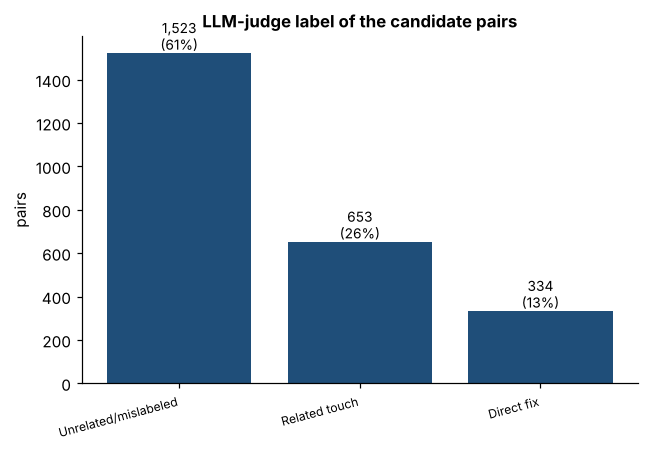

*Exact numbers – LLM-judge label of the candidate pairs*

,number,%
label,,
Unrelated/mislabeled,1523.0,60.7
Related touch,653.0,26.0
Direct fix,334.0,13.3
TOTAL,2510.0,100.0


In [10]:
bar(d["label"].value_counts(), "LLM-judge label of the candidate pairs", "1_judge_labels.png", "pairs", pct=True)

### Chart 2 · Direct fixes per AI agent

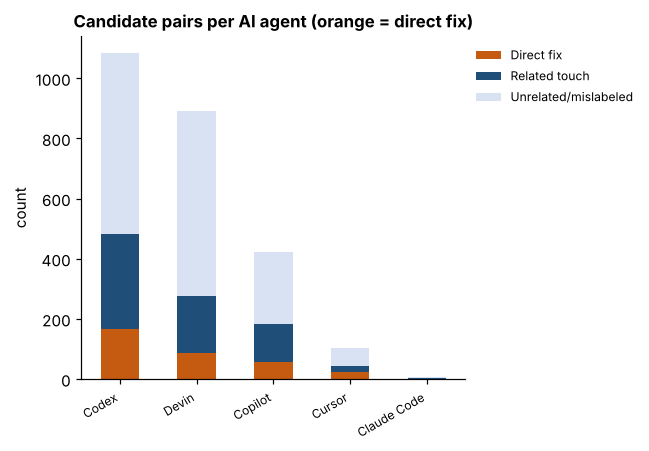

*Exact numbers – Candidate pairs per AI agent (orange = direct fix)*

label,Direct fix,Related touch,Unrelated/mislabeled,TOTAL
agent,,,,
Claude Code,1,1,5,7
Cursor,22,21,59,102
Copilot,56,126,241,423
Devin,88,188,617,893
Codex,167,317,601,1085
TOTAL,334,653,1523,2510


In [11]:
stacked(pd.crosstab(d["agent"], d["label"])[["Direct fix", "Related touch", "Unrelated/mislabeled"]].loc[per_agent.index[::-1]],
        "Candidate pairs per AI agent (orange = direct fix)", "2_direct_fix_per_agent.png", colors=[ORANGE, BLUE, LIGHT])

### Chart 3 · Who wrote the fix PR

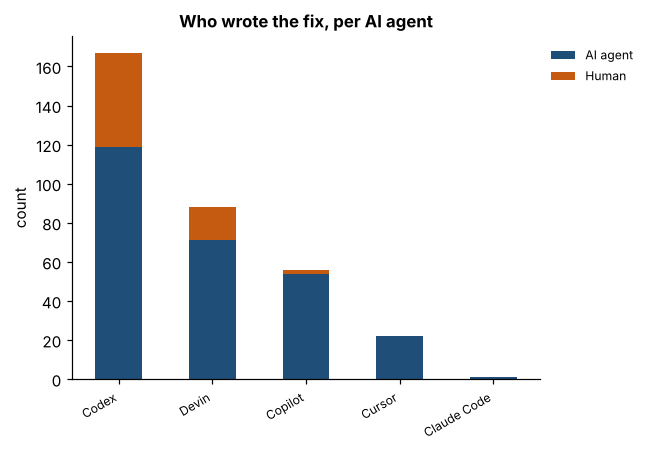

*Exact numbers – Who wrote the fix, per AI agent*

fixed_by,AI agent,Human,TOTAL
agent,,,
Claude Code,1,0,1
Cursor,22,0,22
Copilot,54,2,56
Devin,71,17,88
Codex,119,48,167
TOTAL,267,67,334


In [12]:
stacked(pd.crosstab(fx["agent"], fx["fixed_by"]).loc[per_agent.index[::-1]], "Who wrote the fix, per AI agent", "3_who_fixes.png", colors=[BLUE, ORANGE])

### Chart 4 · How fast the fix comes

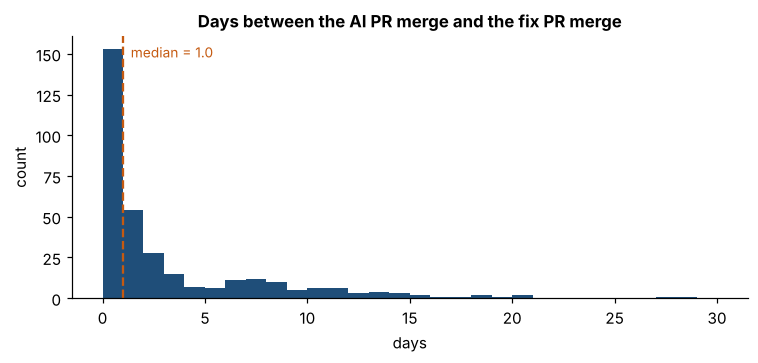

*Exact numbers – Days between the AI PR merge and the fix PR merge*

,count,mean,std,min,25%,median,75%,max
days,334.0,2.87,4.65,0.0,0.0,1.0,3.75,28.0


In [13]:
hist(fx["day_gap"], "Days between the AI PR merge and the fix PR merge", "4_days_to_fix.png", "days", bins=range(0, 31))

### Extra · Language and size of the fixes

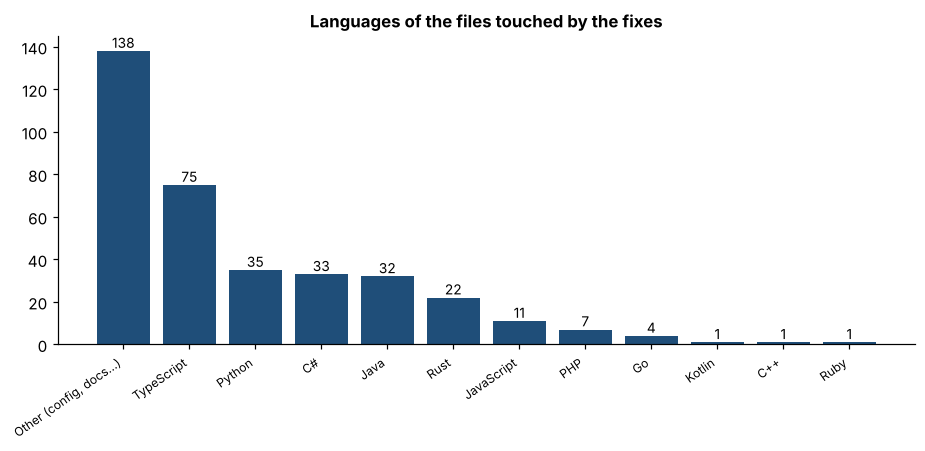

*Exact numbers – Languages of the files touched by the fixes*

,number,%
language,,
"Other (config, docs…)",138.0,38.3
TypeScript,75.0,20.8
Python,35.0,9.7
C#,33.0,9.2
Java,32.0,8.9
Rust,22.0,6.1
JavaScript,11.0,3.1
PHP,7.0,1.9
Go,4.0,1.1


Median lines changed per fixed file: 13.0


In [14]:
EXT = {".py": "Python", ".ts": "TypeScript", ".tsx": "TypeScript", ".js": "JavaScript", ".go": "Go", ".rs": "Rust",
       ".java": "Java", ".cs": "C#", ".rb": "Ruby", ".php": "PHP", ".cpp": "C++", ".kt": "Kotlin"}
files = fx[["pair_id", "agent", "shared"]].explode("shared").dropna(subset=["shared"])
files["file"] = files["shared"].map(lambda s: s.get("name"))
files["language"] = files["file"].map(lambda f: EXT.get(os.path.splitext(str(f))[1].lower(), "Other (config, docs…)"))
files["fix_lines_changed"] = files["shared"].map(lambda s: str(s.get("q_patch") or "").count("\n+") + str(s.get("q_patch") or "").count("\n-"))
bar(files.drop_duplicates(["pair_id", "language"])["language"].value_counts(), "Languages of the files touched by the fixes", "5_fix_languages.png", horizontal=True)
print("Median lines changed per fixed file:", files["fix_lines_changed"].median())

### One real fix (AI PR → fix PR → code change)

In [15]:
ex = fx.iloc[0]
print("AI PR :", ex["p_title"], "|", ex["p_url"])
print("FIX PR:", ex["q_title"], "|", ex["q_url"], "| fixed by", ex["fixed_by"], "|", ex["day_gap"], "days later")
for s in ex["shared"][:2]:
    print("\n--- file:", s["name"]); print(str(s.get("q_patch"))[:1200])

AI PR : refactor: rename X-Agent to X-Engine | https://github.com/jina-ai/reader/pull/1122
FIX PR: fix: clean up X-Agent to X-Engine rename | https://github.com/jina-ai/reader/pull/1123 | fixed by AI agent | 0 days later

--- file: backend/functions/src/cloud-functions/crawler.ts
@@ -759,6 +759,7 @@ export class CrawlerHost extends RPCHost {
         this.threadLocal.set('withImagesSummary', opts.withImagesSummary);
         this.threadLocal.set('keepImgDataUrl', opts.keepImgDataUrl);
         this.threadLocal.set('cacheTolerance', opts.cacheTolerance);
+        this.threadLocal.set('userAgent', opts.userAgent);
         this.threadLocal.set('engine', opts.engine);
         if (opts.timeout) {
             this.threadLocal.set('timeout', opts.timeout * 1000);
@@ -773,6 +774,7 @@ export class CrawlerHost extends RPCHost {
             removeSelector: opts.removeSelector,
             targetSelector: opts.targetSelector,
             waitForSelector: opts.waitForSelector,
+            ov

## 4. Final figure (the 4 charts on one page)

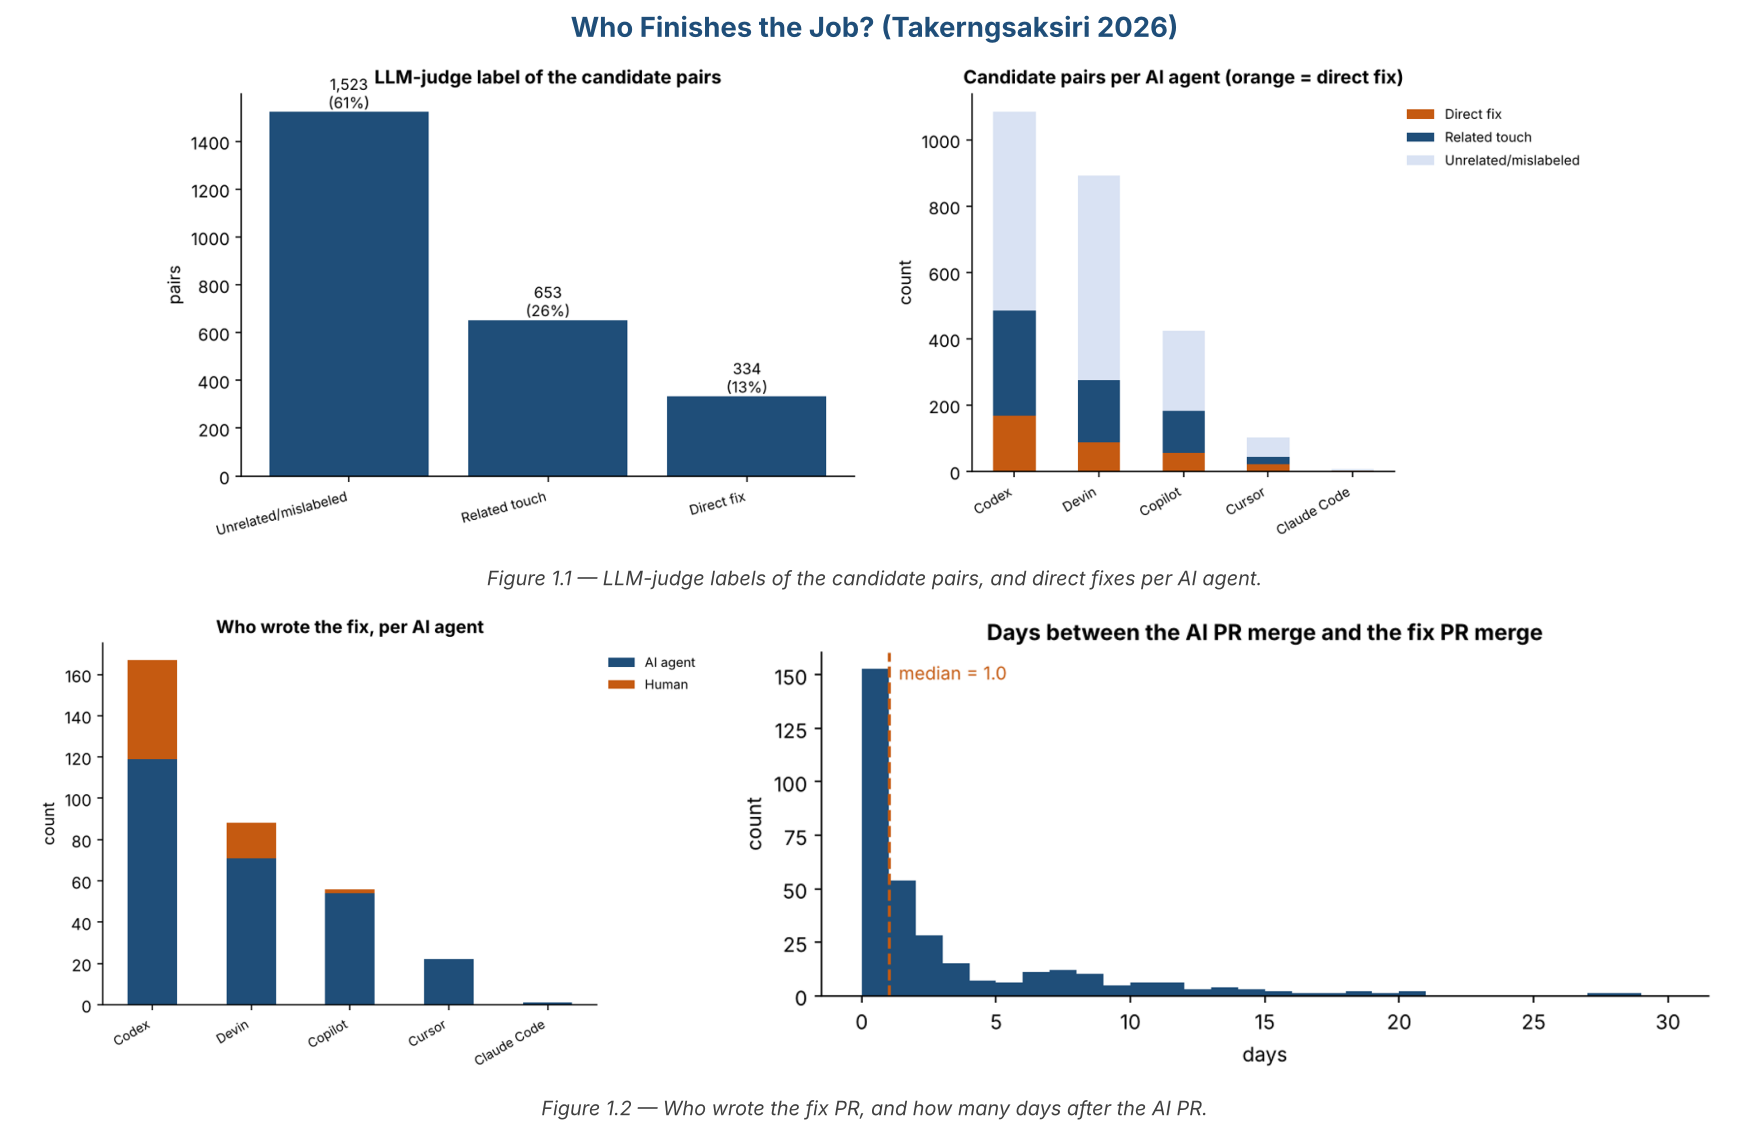

In [16]:
final_figure(1, "Who Finishes the Job? (Takerngsaksiri 2026)",
             "LLM-judge labels of the candidate pairs, and direct fixes per AI agent.",
             "Who wrote the fix PR, and how many days after the AI PR.")

## 5. The fixes in one common format
Each row = one **direct fix**: the AI PR (P) and the later PR (Q) that fixes it, with the real code patch.

The notebook `99_ALL_PAPERS_summary` merges this file from every paper into the **final dataset**.

In [17]:
f = pd.DataFrame({"agent": fx["agent"], "repo": fx["repo"],
    "language": fx["shared"].map(lambda s: lang_of([x.get("name") for x in s]) if isinstance(s, list) else "Other"),
    "level": "PR", "ai_change": fx["p_url"], "fix_change": fx["q_url"], "fixed_by": fx["fixed_by"], "days_to_fix": fx["day_gap"],
    "fix_label": "Direct fix (LLM judge)", "fix_reason": fx["q_title"], "has_code_patch": True})
fixes = save_fixes(f, "Who Finishes 2026")

**334 fixes saved to `tables/fixes.csv`** (same columns in every paper)

,paper,fix_id,agent,repo,language,level,ai_change,fix_change,fixed_by,days_to_fix,fix_label,fix_reason,has_code_patch
8,Who Finishes 2026,WHO-00000,Devin,jina-ai/reader,TypeScript,PR,https://github.com/jina-ai/reader/pull/1122,https://github.com/jina-ai/reader/pull/1123,AI agent,0,Direct fix (LLM judge),fix: clean up X-Agent to X-Engine rename,True
9,Who Finishes 2026,WHO-00001,Devin,jina-ai/reader,TypeScript,PR,https://github.com/jina-ai/reader/pull/1122,https://github.com/jina-ai/reader/pull/1124,AI agent,0,Direct fix (LLM judge),fix: remove duplicate engine declarations,True
10,Who Finishes 2026,WHO-00002,Devin,jina-ai/reader,TypeScript,PR,https://github.com/jina-ai/reader/pull/1123,https://github.com/jina-ai/reader/pull/1124,AI agent,0,Direct fix (LLM judge),fix: remove duplicate engine declarations,True
19,Who Finishes 2026,WHO-00003,Devin,jina-ai/node-DeepResearch,TypeScript,PR,https://github.com/jina-ai/node-DeepResearch/pull/2,https://github.com/jina-ai/node-DeepResearch/pull/9,AI agent,2,Direct fix (LLM judge),fix: standardize TokenTracker imports and usage pattern,True
38,Who Finishes 2026,WHO-00004,Devin,jina-ai/node-DeepResearch,TypeScript,PR,https://github.com/jina-ai/node-DeepResearch/pull/10,https://github.com/jina-ai/node-DeepResearch/pull/58,AI agent,8,Direct fix (LLM judge),fix: update evaluator tests to use proper AnswerAction type,True
